# Fig. 4: Plots

Draws panels (a)–(c) and (d)–(e) of Fig. 4 from the data in `data/pump/` and `data/kappa/`, produced by the notebooks in `notebooks/`. The panels are combined in Inkscape into `figures/fig4.svg` / `figures/fig4.pdf`.

Spectra are stored as $10\log_{10}S$ in dB (negative = squeezing); rates and frequencies (angular frequencies, with the frequency in GHz) are converted to kHz / MHz.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import LogFormatterMathtext

In [2]:
class CustomLogFormatter(LogFormatterMathtext):
    def __call__(self, x, pos=None):
        if np.isclose(x, 1):
            return "1"
        elif np.isclose(x, 10):
            return "10"
        return super().__call__(x, pos)

In [3]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.formatter.use_mathtext": True,
    "font.size": 12,          # general default
    "axes.labelsize": 12,   # X/Y labels
    "xtick.labelsize": 12,   # tick numbers
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.titlesize": 12    # optional
})

## Panels (a)–(c): pump rate $w^{\rm p}$

In [4]:
d = "data/pump/"

P = np.load(d+"P.npy")*1e6/(2*np.pi) # kHz
freqs = np.load(d+"freqs.npy")*1e3/(2*np.pi) # MHz
sq_spec = np.load(d+"Ssq.npy")
emis_spec = np.load(d+"emission.npy")
cond_las = np.transpose(np.load(d+"unstable_normal.npy"))
gap = np.transpose(np.load(d+"linewidth.npy"))*1e6/(2*np.pi) # kHz

pos_eff = np.transpose(np.load(d+"eff_positions.npy"))*1e3/(2*np.pi) # MHz
gap_eff = np.transpose(np.load(d+"eff_widths.npy"))*1e6/(2*np.pi) # kHz

delta = -0.001705123982245429*1e3/(2*np.pi) # Frequency shift Δ of the effective model (MHz)

X, Y = np.meshgrid(freqs,P)

# Emission spectrum normalised to its maximum at each pump rate
emis_norm = emis_spec/np.max(emis_spec, axis=1, keepdims=True)

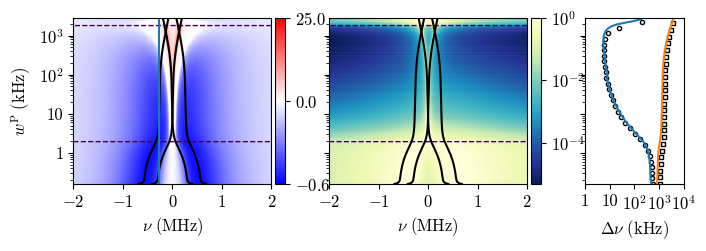

In [5]:
fig = plt.figure(figsize=(3.5*2.25,2.16))

# Axis layout

gs = fig.add_gridspec(1, 3, width_ratios=[1,1,0.5], height_ratios=[1], hspace=0.25, wspace=0.35)

ax_sqspec = fig.add_subplot(gs[0,0])
ax_emis = fig.add_subplot(gs[0,1])
ax_gap = fig.add_subplot(gs[0,2])

# Squeezing spectrum

nrm = mpl.colors.TwoSlopeNorm(vmin=-0.6, vcenter=0, vmax=25)
cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.bwr), cax = ax_sqspec.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$S^\text{sq}_{\hat X}(\nu)\ (\text{dB})$', labelpad=3)
cbar.set_ticks([-0.6, 0, 25])
ax_sqspec.pcolormesh(X, Y, sq_spec, cmap=cm.bwr, norm=nrm, rasterized=True)
ax_sqspec.contour(X, Y, cond_las, levels = [0], linewidths = 1, linestyles = 'dashed')

ax_sqspec.plot(pos_eff[1,:],P, color='black')
ax_sqspec.plot(pos_eff[0,:],P, color='black')
ax_sqspec.plot(-pos_eff[1,:],P, color='black')
ax_sqspec.plot(-pos_eff[0,:],P, color='black')
ax_sqspec.plot([delta,delta],[P.min(),P.max()])

ax_sqspec.set_ylabel(r'$w^\text{P}\ (\text{kHz})$')
ax_sqspec.set_xlabel(r'$\nu\ (\text{MHz})$')
ax_sqspec.set_ylim([P.min(),P.max()])
ax_sqspec.set_xlim([freqs.min(),freqs.max()])
ax_sqspec.set_yscale('log')
ax_sqspec.set_xticks([-2,-1,0,1,2])
ax_sqspec.yaxis.set_major_formatter(CustomLogFormatter())
# ax_sqspec.xaxis.set_major_formatter(CustomLogFormatter())

# Emis. Spectrum

nrm = mpl.colors.LogNorm(vmin=np.min(emis_norm), vmax=np.max(emis_norm))
cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.YlGnBu_r), cax = ax_emis.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$S(\nu)$', labelpad=3) 
ax_emis.pcolormesh(X, Y, emis_norm, cmap=cm.YlGnBu_r, norm=nrm, rasterized=True)
ax_emis.contour(X, Y, cond_las, levels = [0], linewidths = 1, linestyles = 'dashed')

ax_emis.plot(pos_eff[1,:],P, color='black')
ax_emis.plot(pos_eff[0,:],P, color='black')
ax_emis.plot(-pos_eff[1,:],P, color='black')
ax_emis.plot(-pos_eff[0,:],P, color='black')

ax_emis.set_ylim([P.min(),P.max()])
ax_emis.set_xlim([freqs.min(),freqs.max()])
ax_emis.set_xlabel(r'$\nu\ (\text{MHz})$')
ax_emis.set_yscale('log')
ax_emis.yaxis.set_major_formatter(CustomLogFormatter())
ax_emis.tick_params(axis='y',labelleft=False)
ax_emis.yaxis.set_major_formatter(CustomLogFormatter())
ax_emis.set_xticks([-2,-1,0,1,2])
# ax_emis.xaxis.set_major_formatter(CustomLogFormatter())

# # Weight of the peaks

# ax_wei.plot(wei_rel_1_0,P, color='black')
# ax_wei.plot(wei_rel_2_0,P, color='green')

# ax_wei.set_yscale('log')
# ax_wei.set_xlim([np.min(0),np.max(1)])
# ax_wei.set_ylim([P.min(),P.max()])
# ax_wei.set_xlabel(r'Weight')
# ax_wei.yaxis.set_major_formatter(CustomLogFormatter())
# ax_wei.tick_params(axis='y',labelleft=False)

# Liouv. Gap

ax_gap.plot(gap[3,:],P, '.', fillstyle='none', markeredgewidth=1, color='black', markevery=5, markersize=6)
ax_gap.plot(gap[2,:],P, 's', fillstyle='none', markeredgewidth=1, color='black', markevery=6, markersize=3)
ax_gap.plot(gap_eff[1,:],P)
ax_gap.plot(gap_eff[0,:],P)
ax_gap.set_yscale('log')
ax_gap.set_xscale('log')
ax_gap.set_xlim([1,1e4])
ax_gap.set_ylim([P.min(),P.max()])
ax_gap.set_xlabel(r'$\Delta\nu\ (\text{kHz})$')
ax_gap.tick_params(axis='y',labelleft=False)
ax_gap.set_xticks([1,10,100,1000,10000])
ax_gap.yaxis.set_major_formatter(CustomLogFormatter())
ax_gap.xaxis.set_major_formatter(CustomLogFormatter())

plt.savefig("figures/panels_abc.svg", bbox_inches="tight")
plt.show()

## Panels (d)–(e): cavity decay $\kappa$

In [6]:
d = "data/kappa/"

kappa = np.load(d+"kappa.npy")*1e6/(2*np.pi) # kHz
freqs = np.load(d+"freqs.npy")*1e3/(2*np.pi) # MHz
sq_spec = np.load(d+"Ssq_full.npy")
sq_spec_eff = np.load(d+"Ssq_eff.npy")
pos_eff = np.transpose(np.load(d+"eff_positions.npy"))*1e3/(2*np.pi) # MHz
equal = np.load(d+"kappa_ratio.npy") # |κ/κ̃ - 1|

X, Y = np.meshgrid(freqs,kappa)

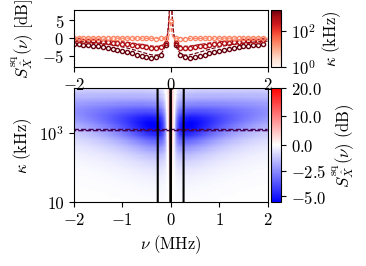

In [7]:
fig = plt.figure(figsize=(2.5,2.5))

# Axis layout

gs = fig.add_gridspec(2, 1, width_ratios=[1], height_ratios=[0.5,1], hspace=0.25, wspace=0.35)

ax_sqspec = fig.add_subplot(gs[1,0])
ax_cut = fig.add_subplot(gs[0,0])

# Squeezing spectrum

nrm = mpl.colors.TwoSlopeNorm(vmin=sq_spec.min(), vcenter=0, vmax=20)
cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.bwr), cax = ax_sqspec.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$S^\text{sq}_{\hat X}(\nu)\ (\text{dB})$', labelpad=3)
cbar.set_ticks([20, 10, 0, -2.5, -5])
ax_sqspec.pcolormesh(X, Y, sq_spec, cmap=cm.bwr, norm=nrm, rasterized=True)
ax_sqspec.contour(X, Y, equal, levels = [0.04], linewidths = 1, linestyles = 'dashed')

ax_sqspec.plot(pos_eff[1,:],kappa, color='black', markersize=2)
ax_sqspec.plot(pos_eff[0,:],kappa, color='black', markersize=2)
ax_sqspec.plot(-pos_eff[1,:],kappa, color='black', markersize=2)
ax_sqspec.plot(-pos_eff[0,:],kappa, color='black', markersize=2)

ax_sqspec.set_xlabel(r'$\nu\ (\text{MHz})$')
ax_sqspec.set_ylabel(r'$\kappa\ (\text{kHz})$')
ax_sqspec.set_ylim([kappa.min(),kappa.max()])
ax_sqspec.set_xlim([-2,2])
ax_sqspec.set_yscale('log')
ax_sqspec.set_xticks([-2,-1,0,1,2])
ax_sqspec.yaxis.set_major_formatter(CustomLogFormatter())
# ax_sqspec.xaxis.set_major_formatter(CustomLogFormatter())

# Spectrum cuts

# Top axis

ind_k = [65,50,9] # Cuts shown in the top axis (κ ≈ 1500, 450, 20 kHz)

cmap2 = plt.get_cmap('Reds')
nrm2 = mpl.colors.LogNorm(1,1500)

for i in range(3):
    ax_cut.plot(freqs,sq_spec[ind_k[i],:], '.', fillstyle='none', markeredgewidth=1, color=cmap2(nrm2(kappa[ind_k[i]])), markevery=50, markersize=6)
    ax_cut.plot(freqs,sq_spec_eff[ind_k[i],:], color=cmap2(nrm2(kappa[ind_k[i]])), linewidth=0.8, linestyle='dashed')

cbar_2 = plt.colorbar(cm.ScalarMappable(norm=nrm2, cmap=cmap2), cax = ax_cut.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar_2.set_label(r'$\kappa\ (\text{kHz})$', labelpad=3) 

ax_cut.set_ylabel(r'$S_{\hat X}^\text{sq}(\nu)\ \text{[dB]}$')
ax_cut.set_ylim([-8,8])
ax_cut.set_xlim([-2,2])

plt.savefig("figures/panels_de.svg", bbox_inches="tight")
plt.show()